In [27]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [28]:
import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent))

import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

np.random.seed(2025)

from ipywidgets import interact, FloatSlider, IntSlider
import matplotlib.patches as patches

from src.SHRED import SHRED, fit, predict
from src.SHRED_GRUD import SHRED_GRUD, fit, predict
from src.processdata import TimeSeriesDataset, Padding, PaddingGRUD
from src.utils import dim_reduction, num2p, mre, mse, mae, rmse


## **Double gyre flow**

The double gyre flow is a time-dependent model for two counter-rotating vortices (gyres) in a rectangular domain. When time is introduced via a periodic perturbation, the central dividing line between the two gyres oscillates left and right, creating a time-varying velocity field that can lead to chaotic particle trajectories. The velocity field $\mathbf{v} = [u, v]^T$ in the domain $[0, L_x] \times [0, L_y]$ and in the time interval $[0, T]$ is given by

$$
\begin{align}
u(x, y, t) &= -\pi I \sin\left( \pi f(x, t) \right) \cos\left( \pi y \right)
\\
v(x, y, t) &= \pi I \cos\left( \pi f(x, t) \right) \sin\left( \pi y \right) \frac{\partial f}{\partial x}
\end{align}
$$

\
where $I$ is the intensity parameter, $f(x, t) = \epsilon \sin(\omega t) x^2 + (1 - 2\epsilon \sin(\omega t)) x $, $\epsilon$ and $\omega$ are the perturbation amplitude and the frequency of the oscillation, respectively.

## Solver

In [29]:
# DEFINE THE SYSTEM SOLVER

def double_gyre_flow(amplitude, frequency, x, y, t):
    '''
    Solve the double gyre flow problem

    Inputs
        amplitude                   (`float`)
        frequency                   (`float`)
        horizontal discretization   (`np.array[float]`, shape: (ny,))
        vertical discretization     (`np.array[float]`, shape: (nx,))
        time vector                 (`np.array[float]`, shape: (ntimes,))

    Output
        horizontal velocity matrix  (`np.array[float]`, shape: (ntimes, nx * ny)
        vertical velocity matrix    (`np.array[float]`, shape: (ntimes, nx * ny)
    '''

    xgrid, ygrid = np.meshgrid(x, y)         # spatial grid

    u = np.zeros((len(t), len(x), len(y)))   # horizontal velocity
    v = np.zeros((len(t), len(x), len(y)))   # vertical velocity

    intensity = 0.1   # intensity parameter

    f = lambda x,t: amplitude * np.sin(frequency * t) * x**2 + x - 2 * amplitude * np.sin(frequency * t) * x

    # compute solution
    for i in range(len(t)):
      u[i] = (-np.pi * intensity * np.sin(np.pi * f(xgrid, t[i])) * np.cos(np.pi * ygrid)).T
      v[i] = (np.pi * intensity * np.cos(np.pi * f(xgrid, t[i])) * np.sin(np.pi * ygrid) * (2 * amplitude * np.sin(frequency * t[i]) * xgrid + 1.0 - 2 * amplitude * np.sin(frequency * t[i]))).T

    return u, v

In [30]:
# DATA GENERATION

amplitude_range = np.array([0.0, 0.5])
frequency_range = np.array([0.5, 2*np.pi])

# spatial discretization
nx = 50
ny = 25
Lx = 2.0
Ly = 1.0
x = np.linspace(0, Lx, nx)
y = np.linspace(0, Ly, ny)
nstate = len(x) * len(y)

# temporal discretization
dt = 0.1
T = 10.0
t = np.arange(0, T + dt, dt)
ntimes = len(t)

# training data generation
ntrajectories = 100
U = np.zeros((ntrajectories, ntimes, nx, ny))
V = np.zeros((ntrajectories, ntimes, nx, ny))

for i in range(ntrajectories):
  amplitude = (amplitude_range[1] - amplitude_range[0]) * np.random.rand() + amplitude_range[0]
  frequency = (frequency_range[1] - frequency_range[0]) * np.random.rand() + frequency_range[0]
  U[i], V[i] = double_gyre_flow(amplitude, frequency, x, y, t)

# VORTICITY CALCULATION
def vorticity(u, v):
    dx = Lx / nx
    dy = Ly / ny
    du_dy = np.gradient(u, dy, axis = 1)
    dv_dx = np.gradient(v, dx, axis = 0)
    return dv_dx - du_dy

In [31]:
# DATA VISUALIZATION

def plot_data(which_trajectory, which_time):

    offset = 0.1

    plt.figure(figsize = (10,5))
    plt.contourf(x, y, vorticity(U[which_trajectory, which_time], V[which_trajectory, which_time]).T, cmap = 'seismic', levels = 100)
    plt.streamplot(x, y, U[which_trajectory, which_time].T, V[which_trajectory, which_time].T, color='black', linewidth = 1, density = 1)
    plt.axis('off')
    plt.axis([0 - offset, Lx + offset, 0 - offset, Ly + offset])
    plt.title(f'Trajectory {which_trajectory} at time t = {round(t[which_time], 3)}')
    plt.grid(True)
    plt.gca().add_patch(patches.Rectangle((0, 0), Lx, Ly, linewidth = 5, edgecolor = 'black', facecolor = 'none'))

interact(
    plot_data, 
    which_trajectory = IntSlider(min = 0, max = ntrajectories - 1, step = 1, description='Trajectory'), 
    which_time = IntSlider(min = 0, max = ntimes - 1, step = 1, description='Time step')
);

interactive(children=(IntSlider(value=0, description='Trajectory', max=99), IntSlider(value=0, description='Ti…

In [32]:
# TORCH CONVERSION

U = torch.from_numpy(U.reshape(ntrajectories, ntimes, nstate))
V = torch.from_numpy(V.reshape(ntrajectories, ntimes, nstate))

print(f'U shape: {U.shape} \nV shape: {V.shape}')

U shape: torch.Size([100, 101, 1250]) 
V shape: torch.Size([100, 101, 1250])


## Broken sensors simulations

In [33]:
# EXTRACT SENSORS DATA

nsensors = 3
short_broken = 1
long_broken = 1 

idx_sensors = np.random.choice(nstate, size = nsensors, replace = False)
idx_short_broken_s = idx_sensors[0:short_broken]
idx_long_broken_s = idx_sensors[short_broken:short_broken+long_broken]

print("Available sensors:\t", idx_sensors)
print("short broken sensors:\t", idx_short_broken_s)
print("long broken sensors:\t", idx_long_broken_s)

sensors_data = U[:,:,idx_sensors]

idx_sensors_x, idx_sensors_y = np.unravel_index(idx_sensors, (nx, ny))
sensors_coordinates = np.vstack((x[idx_sensors_x], y[idx_sensors_y]))

Available sensors:	 [690 587 929]
short broken sensors:	 [690]
long broken sensors:	 [587]


In [34]:
# SHORT BROKEN SIMULATION

# broken = bernoulli distribution
p_short_broken = 0.2
for idx in idx_short_broken_s:
    local_idx = np.where(idx_sensors == idx)[0][0]

    mask_train = torch.rand(sensors_data[:, :, local_idx].shape) < p_short_broken
    print("simulation of short broken sensor idx\t", idx, "\twith probability", p_short_broken)

    sensors_data[:, :, local_idx][mask_train] = float('nan')


# LONG BROKEN SIMULATION

#draw 2 numbers and erase in the middle
for idx in idx_long_broken_s:
    local_idx = np.where(idx_sensors == idx)[0][0]

    t1, t2 = np.random.randint(0, ntimes, size=2)
    t_start, t_end = min(t1, t2), max(t1, t2)
    if t_end - t_start < 30: # if the interval is too short, make it longer
        t_end = min(t_start + 38, ntimes-1)
    print("simulation of long broken sensor idx\t", idx, "\tfrom time step", t_start, "to time step", t_end)

    sensors_data[:, t_start:t_end + 1, local_idx] = float('nan')

simulation of short broken sensor idx	 690 	with probability 0.2
simulation of long broken sensor idx	 587 	from time step 42 to time step 80


In [35]:
# PLOT DATA AVAILABILITY

def plot_data_availability(sensor_data, title_prefix, trajectory=0, sensor_labels=None):
    traj_idx = min(trajectory, sensor_data.shape[0] - 1)
    availability = (~torch.isnan(sensor_data[traj_idx])).to(torch.float32).cpu().numpy()
    time = np.arange(availability.shape[0])
    nsensors_plot = availability.shape[1]

    if sensor_labels is None:
        sensor_labels = np.arange(nsensors_plot)
    sensor_labels = np.asarray(sensor_labels)

    if sensor_labels.shape[0] != nsensors_plot:
        raise ValueError("sensor_labels length must match number of sensor columns")

    fig_height = max(3.0, 0.7 * nsensors_plot)
    _, ax = plt.subplots(1, 1, figsize=(14, fig_height))

    for sensor_idx in range(nsensors_plot):
        line = np.where(availability[:, sensor_idx] > 0.5, sensor_idx + 1.0, np.nan)
        ax.plot(time, line, linewidth=4, solid_capstyle="butt", label=f"S{sensor_labels[sensor_idx]}")

    ax.set_xlabel("Time step")
    ax.set_ylabel("Sensor")
    ax.set_yticks(np.arange(1, nsensors_plot + 1))
    ax.set_yticklabels([f"S{label}" for label in sensor_labels])
    ax.set_ylim(0.5, nsensors_plot + 0.5)
    ax.grid(True, axis="x", alpha=0.25)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="Sensors")

    plt.title(f"{title_prefix} - Trajectory {traj_idx}")
    plt.tight_layout()
    plt.show()

In [36]:
def plot_train_data_availability(trajectory=0):
    plot_data_availability(
        sensors_data,
        "Train availability",
        trajectory,
        sensor_labels=np.arange(sensors_data.shape[2])
    )

interact(
    plot_train_data_availability,
    trajectory=IntSlider(min=0, max=sensors_data.shape[0] - 1, step=1, value=0, description="Trajectory"),
);

interactive(children=(IntSlider(value=0, description='Trajectory', max=99), Output()), _dom_classes=('widget-i…

In [37]:
print("U shape: \t", U.shape)
print("V shape: \t", V.shape)
print("input shape: \t", sensors_data.shape)

U shape: 	 torch.Size([100, 101, 1250])
V shape: 	 torch.Size([100, 101, 1250])
input shape: 	 torch.Size([100, 101, 3])


## TRAIN VAL TEST split

In [38]:
## Splitting the data into train, valid and test sets

#split the sizes
train_size = int(0.8 * ntrajectories)
val_size = int(0.1 * ntrajectories)
test_size = ntrajectories - train_size - val_size
print(f"Train size: {train_size} \nValidation size: {val_size} \nTest size: {test_size}")

#shuffle the data
shuffle_indices = torch.randperm(ntrajectories)
U = U[shuffle_indices]
V = V[shuffle_indices]
sensors_data = sensors_data[shuffle_indices]

#split the data
U_train, U_val, U_test = torch.split(U, [train_size, val_size, test_size], dim=0)
V_train, V_val, V_test = torch.split(V, [train_size, val_size, test_size], dim=0)
input_train, input_val, input_test = torch.split(sensors_data, [train_size, val_size, test_size], dim=0)
print(f"\nU_train shape:\t{U_train.shape} \nV_train shape:\t{V_train.shape} \ninput_train shape:\t{input_train.shape}")
print(f"\nU_val shape:\t{U_val.shape} \nV_val shape:\t{V_val.shape} \ninput_val shape:\t{input_val.shape}")
print(f"\nU_test shape:\t{U_test.shape} \nV_test shape:\t{V_test.shape} \ninput_test shape:\t{input_test.shape}")

Train size: 80 
Validation size: 10 
Test size: 10

U_train shape:	torch.Size([80, 101, 1250]) 
V_train shape:	torch.Size([80, 101, 1250]) 
input_train shape:	torch.Size([80, 101, 3])

U_val shape:	torch.Size([10, 101, 1250]) 
V_val shape:	torch.Size([10, 101, 1250]) 
input_val shape:	torch.Size([10, 101, 3])

U_test shape:	torch.Size([10, 101, 1250]) 
V_test shape:	torch.Size([10, 101, 1250]) 
input_test shape:	torch.Size([10, 101, 3])


## POD based reduction

Residual energy is equal to  7.434566149416012e-07



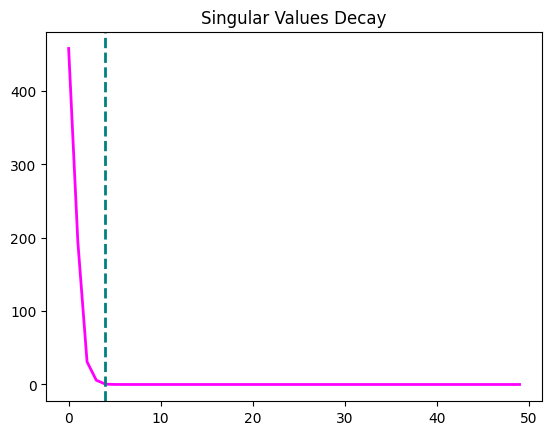

Residual energy is equal to  6.293836315726633e-06



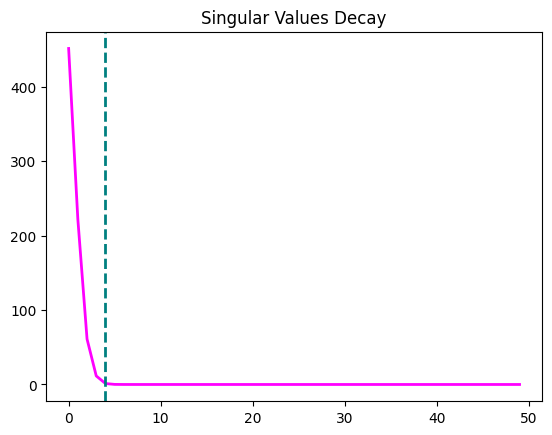

In [39]:
POD_modes = 4

## Dimensionality reduction with POD

U_train, U_val, U_test, U_train_proj, U_val_proj, U_test_proj, V1_POD = dim_reduction(U_train, U_val, U_test, POD_modes)
V_train, V_val, V_test, V_train_proj, V_val_proj, V_test_proj, V2_POD = dim_reduction(V_train, V_val, V_test, POD_modes)

In [40]:
print(f'U_train shape:\t\t{U_train.shape}')
print(f'U_train_proj shape:\t{U_train_proj.shape}')
print(f'V_train shape:\t\t{V_train.shape}')
print(f'V_train_proj shape:\t{V_train_proj.shape}')

U_train shape:		torch.Size([80, 101, 1250])
U_train_proj shape:	torch.Size([80, 101, 4])
V_train shape:		torch.Size([80, 101, 1250])
V_train_proj shape:	torch.Size([80, 101, 4])


## **Idea 2: GRUD** 

In [41]:

interact(
    plot_train_data_availability,
    trajectory=IntSlider(min=0, max=sensors_data.shape[0] - 1, step=1, value=0, description="Trajectory"),
);

interactive(children=(IntSlider(value=0, description='Trajectory', max=99), Output()), _dom_classes=('widget-i…

In [42]:
# x must be shaped (batch_size, 4, seq_len, input_size)
# The 4 channels are: X, X_last_obsv, Mask, Delta

def create_GRUD_input(input_data):
    n_traj = input_data.shape[0]
    input_tensor = torch.zeros(n_traj, 4, ntimes, nsensors)

    for idx in range(n_traj):
        for sensor in range(nsensors):

            series = input_data[idx, :, sensor]

            # channel 0: raw values (NaN kept as 0 in the tensor)
            input_tensor[idx, 0, :, sensor] = torch.nan_to_num(series, nan=0.0)

            for t in range(1, ntimes):
                if torch.isnan(series[t]):
                    # missing: carry forward last observed, mask=0, increment delta
                    input_tensor[idx, 1, t, sensor] = input_tensor[idx, 1, t-1, sensor]
                    input_tensor[idx, 2, t, sensor] = 0.0
                    input_tensor[idx, 3, t, sensor] = input_tensor[idx, 3, t-1, sensor] + 1.0
                else:
                    # observed: store value, mask=1, reset delta
                    input_tensor[idx, 1, t, sensor] = series[t]
                    input_tensor[idx, 2, t, sensor] = 1.0
                    input_tensor[idx, 3, t, sensor] = 0.0

    return input_tensor


In [43]:
# create the input tensors for the GRU-D model  (ntrajectories, 4, ntimes, nsensors)
input_train_grud = create_GRUD_input(input_train)
input_val_grud   = create_GRUD_input(input_val)
input_test_grud  = create_GRUD_input(input_test)

print(f"input_train_grud shape: {input_train_grud.shape}")
print(f"channels: [X, X_last_obsv, Mask, Delta]")


input_train_grud shape: torch.Size([80, 4, 101, 3])
channels: [X, X_last_obsv, Mask, Delta]


In [44]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

lag = 25

# Apply sliding-window padding to the 4-channel GRU-D tensors
train_data_in_grud = PaddingGRUD(input_train_grud, lag).to(device)  # (n_train*ntimes, 4, lag, nsensors)
valid_data_in_grud = PaddingGRUD(input_val_grud,   lag).to(device)
test_data_in_grud  = PaddingGRUD(input_test_grud,  lag).to(device)

train_data_out = Padding(torch.cat((U_train_proj, V_train_proj), 2), 1).squeeze(1).to(device)
valid_data_out = Padding(torch.cat((U_val_proj,   V_val_proj),   2), 1).squeeze(1).to(device)
test_data_out  = Padding(torch.cat((U_test_proj,  V_test_proj),  2), 1).squeeze(1).to(device)

train_dataset_grud = TimeSeriesDataset(train_data_in_grud, train_data_out)
valid_dataset_grud = TimeSeriesDataset(valid_data_in_grud, valid_data_out)
test_dataset_grud  = TimeSeriesDataset(test_data_in_grud,  test_data_out)

print(f"Train:  {train_data_in_grud.shape} -> {train_data_out.shape}")
print(f"Val:    {valid_data_in_grud.shape} -> {valid_data_out.shape}")
print(f"Test:   {test_data_in_grud.shape } -> {test_data_out.shape}")


Using device: cpu
Train:  torch.Size([8080, 4, 25, 3]) -> torch.Size([8080, 8])
Val:    torch.Size([1010, 4, 25, 3]) -> torch.Size([1010, 8])
Test:   torch.Size([1010, 4, 25, 3]) -> torch.Size([1010, 8])


In [45]:
# X_mean: mean of the X channel (ch 0) across training trajectories
# shape must be (1, ntimes, nsensors) because GRUD indexes it as X_mean[:, i:i+1, :]
X_mean = input_train_grud[:, 0, :, :].mean(dim=0, keepdim=True).to(device)
print(f"Input mean shape: {X_mean.shape}")  # expected: (1, ntimes, nsensors)


Input mean shape: torch.Size([1, 101, 3])


In [50]:
shred_grud = SHRED_GRUD(
    nsensors, 2*POD_modes, X_mean, hidden_size=32, decoder_sizes=[], dropout=0.1
)
train_errors, valid_errors = fit(
    shred_grud,
    train_dataset_grud,
    valid_dataset_grud,
    epochs=300,
    batch_size=32,
    lr=1e-3,
    verbose=True,
    patience=40
)


Training: 100%|██████████| 300/300 [09:20<00:00,  1.87s/it, Train Error=0.58%, Val Error=0.58%, Patience=9] 

Training Complete (300 epochs)


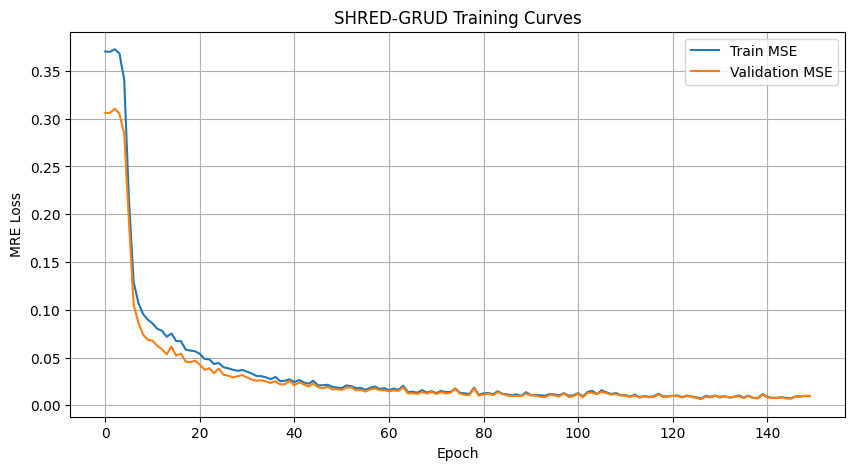

In [53]:
# PLOT TRAINING CURVES
steps = 150

plt.figure(figsize=(10, 5))
plt.plot(train_errors[0:steps], label='Train MSE')
plt.plot(valid_errors[0:steps], label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MRE Loss')
plt.title('SHRED-GRUD Training Curves')
plt.legend()
plt.grid()
plt.show()

In [61]:
shred_grud.freeze()

UVtest_hat_grud = shred_grud(test_data_in_grud).to(torch.float64)

Utest_hat = UVtest_hat_grud[:, :POD_modes] @ V1_POD[:POD_modes, :]
Utest_hat = Utest_hat.reshape(test_size, ntimes, nx, ny)
Utest = U_test.reshape(test_size, ntimes, nx, ny)

Vtest_hat = UVtest_hat_grud[:, POD_modes:] @ V2_POD[:POD_modes, :]
Vtest_hat = Vtest_hat.reshape(test_size, ntimes, nx, ny)
Vtest = V_test.reshape(test_size, ntimes, nx, ny)

def plot_shred_reconstruction(which_test_trajectory, which_time):
    offset = 0.1

    fig, axes = plt.subplots(1, 2, figsize=(20, 5))

    for ax, field_u, field_v, title in zip(
        axes,
        [Utest[which_test_trajectory, which_time],     Utest_hat[which_test_trajectory, which_time]],
        [Vtest[which_test_trajectory, which_time],     Vtest_hat[which_test_trajectory, which_time]],
        [f'Test case {which_test_trajectory} at t = {round(t[which_time], 3)}',
         f'SHRED-GRUD reconstruction at t = {round(t[which_time], 3)}']
    ):
        ax.contourf(x, y, vorticity(field_u, field_v).T, cmap='seismic', levels=100)
        ax.streamplot(x, y, field_u.T, field_v.T, color='black', linewidth=1, density=1)
        ax.axis('off')
        ax.axis([0 - offset, Lx + offset, 0 - offset, Ly + offset])
        ax.set_title(title)
        ax.add_patch(patches.Rectangle((0, 0), Lx, Ly, linewidth=5, edgecolor='black', facecolor='none'))
        for k in range(nsensors):
            ax.plot(
                sensors_coordinates[0, k], sensors_coordinates[1, k],
                'o', mfc='magenta', mec='black', ms=12, mew=2.0,
                label='Sensor' if k == 0 else None
            )
        ax.legend(loc='upper right', frameon=True)

    plt.tight_layout()
    plt.show()

interact(
    plot_shred_reconstruction,
    which_test_trajectory=IntSlider(value=0, min=0, max=test_size - 1, description='Test case'),
    which_time=IntSlider(min=0, max=ntimes - 1, step=1, description='Time step')
);


interactive(children=(IntSlider(value=0, description='Test case', max=9), IntSlider(value=0, description='Time…